# Retinal Vascular Graph Stability Analysis

Topology and geometry sensitivity using the official HRF and CHASE_DB1 retinal vessel datasets.

In [1]:
from pathlib import Path
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from retina_graph.data import ensure_hrf_data, ensure_chase_data, iter_all_samples
from retina_graph.graph_features import perturbation_set, extract_graph_features
from retina_graph.experiment import run_graph_experiment
from skimage.morphology import skeletonize

HRF_ROOT = ensure_hrf_data(ROOT)
INCLUDE_CHASE = os.environ.get("INCLUDE_CHASE", "0") == "1"
CHASE_ROOT = ensure_chase_data(ROOT) if INCLUDE_CHASE else None
RESULTS = ROOT / "results"

## Inspect an expert retinal vessel graph

,value
graph_node_count,357.000000
branch_count,406.000000
endpoint_count,144.000000
junction_count,209.000000
graph_component_count,7.000000
total_branch_length_px,61071.531860
mean_branch_length_px,150.422492
mean_tortuosity,1.116381
mean_smoothed_tortuosity,1.072189
median_vessel_diameter_px,5.656854


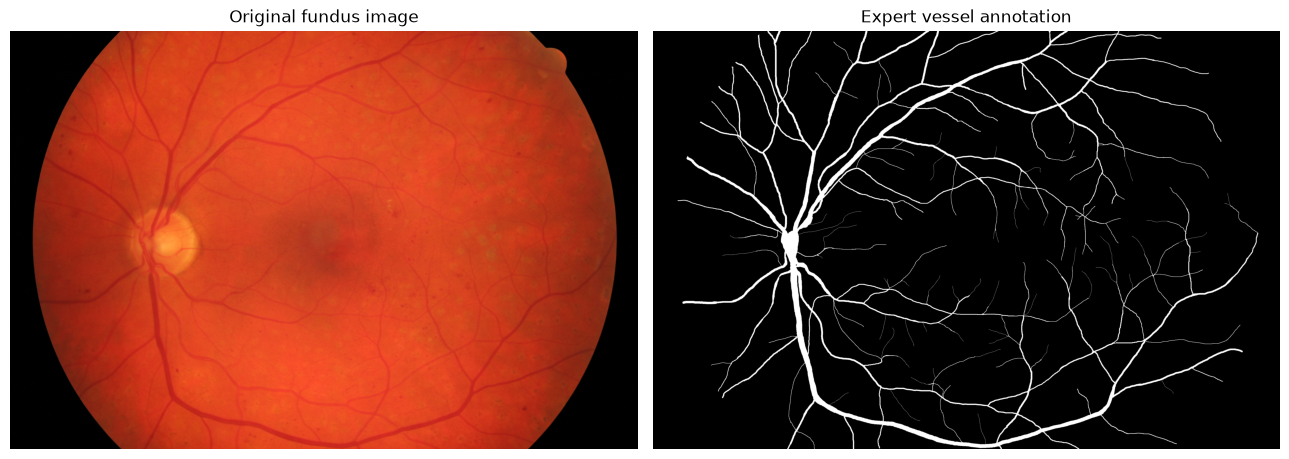

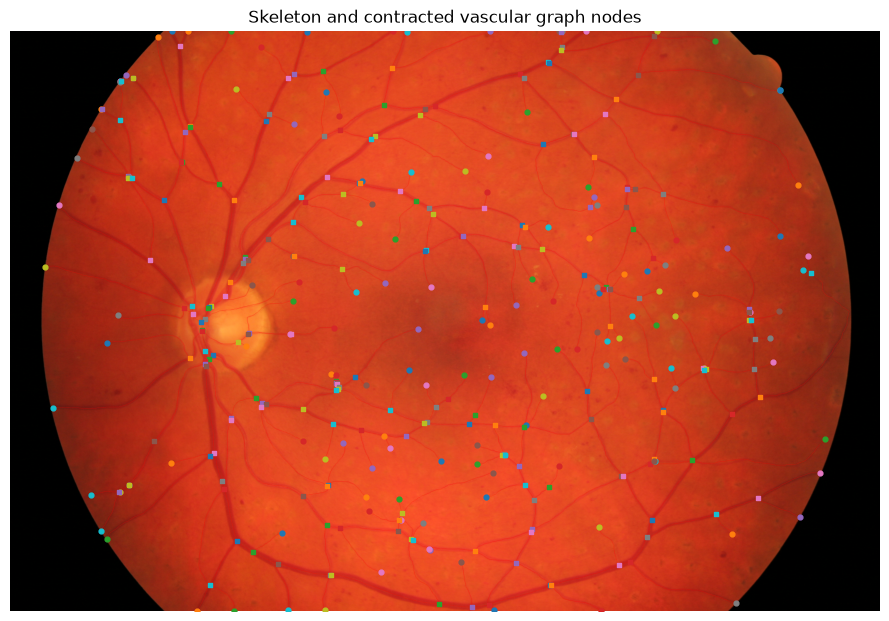

In [2]:
sample = next(iter_all_samples(HRF_ROOT, CHASE_ROOT, include_chase=False))
metrics, graph, branches = extract_graph_features(sample.vessel_mask, sample.fov_mask)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(sample.image)
axes[0].set_title("Original fundus image")
axes[1].imshow(sample.vessel_mask, cmap="gray")
axes[1].set_title("Expert vessel annotation")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

skeleton = skeletonize(sample.vessel_mask & sample.fov_mask)
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(sample.image)
ax.imshow(__import__("numpy").ma.masked_where(~skeleton, skeleton), cmap="autumn", alpha=0.75)
for node_id, attributes in graph.nodes(data=True):
    marker = "s" if attributes["node_type"] == "junction" else "o"
    ax.scatter(attributes["x"], attributes["y"], marker=marker, s=12)
ax.set_title("Skeleton and contracted vascular graph nodes")
ax.axis("off")
plt.tight_layout()
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS / "figures" / "example_graph_overlay.png", dpi=180)

pd.Series(metrics).to_frame("value")

## Extract branch and graph measurements under controlled perturbations

In [3]:
per_image, branch_features, summary = run_graph_experiment(
    HRF_ROOT,
    RESULTS,
    chase_root=CHASE_ROOT,
    include_chase=INCLUDE_CHASE,
    sample_limit=int(os.environ.get("RETINA_SAMPLE_LIMIT", "0")) or None,
    prune_length_px=5.0,
)
summary


KeyboardInterrupt



In [4]:
per_image, branch_features, summary = run_graph_experiment(
    HRF_ROOT,
    RESULTS,
    chase_root=CHASE_ROOT,
    include_chase=INCLUDE_CHASE,
    sample_limit=3,
    prune_length_px=5.0,
)
summary

,dataset,condition,images,graph_node_count_change_pct,branch_count_change_pct,endpoint_count_change_pct,junction_count_change_pct,graph_component_count_change_pct,total_branch_length_px_change_pct,mean_branch_length_px_change_pct,mean_tortuosity_change_pct,mean_smoothed_tortuosity_change_pct,median_vessel_diameter_px_change_pct,pruned_branch_count_change_pct,pruned_total_length_px_change_pct,pruned_endpoint_count_change_pct,pruned_junction_count_change_pct,pruned_component_count_change_pct,skeleton_pixel_count_change_pct
0,HRF,original,3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,HRF,erosion_r1,3,473.188481,101.448909,691.674934,-23.391155,47995.238095,-16.386315,-50.786951,-4.894461,-2.985043,-57.795874,1.051655,-18.015337,105.740466,-25.637472,1210.185185,-14.223612
2,HRF,erosion_r2,3,301.272913,64.759376,529.862765,-44.024192,22893.650794,-34.208060,-58.788336,-5.434317,-3.243431,-68.096441,-16.009954,-35.574709,103.097323,-47.642479,1409.259259,-33.137967
3,HRF,dilation_r1,3,-1.062587,-0.387665,-3.700397,1.496265,-30.158730,-0.401309,0.091521,-0.116153,-0.116737,23.875485,0.892924,-0.397495,-0.904477,2.232667,-3.703704,-0.494187


## Compare sensitivity across datasets

branch_count  endpoint_count  junction_count  \
dataset condition                                                   
HRF     dilation_r1    631.000000      231.666667      333.000000   
        erosion_r1    1197.666667     1613.333333      255.000000   
        erosion_r2    1076.000000     1578.666667      188.333333   
        original       628.666667      238.666667      327.000000   

                     total_branch_length_px  mean_tortuosity  \
dataset condition                                              
HRF     dilation_r1            75938.390009         1.098611   
        erosion_r1             64464.457983         1.045943   
        erosion_r2             50846.506290         1.040106   
        original               76249.190682         1.099980   

                     median_vessel_diameter_px  
dataset condition                               
HRF     dilation_r1                   7.932230  
        erosion_r1                    2.824045  
        erosion_r2                    2.000000  
        original                      6.437903

,dataset,image_id,condition,branch_index,length_px,tortuosity,smoothed_tortuosity,mean_diameter_px,median_diameter_px,source,target
0,HRF,01_dr,original,0,79.740114,1.221148,1.159613,7.804471,8.246211,0,146
1,HRF,01_dr,original,1,75.183766,1.126673,1.057364,10.658445,10.770330,1,146
2,HRF,01_dr,original,2,451.274166,1.087938,1.037994,5.725406,5.656854,2,171
3,HRF,01_dr,original,3,348.445739,1.076327,1.012421,10.918424,10.770330,3,152
4,HRF,01_dr,original,4,455.717817,1.081867,1.017611,5.686017,5.656854,4,151
5,HRF,01_dr,original,5,6.242641,1.070604,1.014453,7.078689,7.000000,5,144
6,HRF,01_dr,original,6,122.681239,1.065666,1.011094,10.652543,11.313708,6,147
7,HRF,01_dr,original,7,4.828427,1.079669,1.007759,7.231075,7.211103,7,144
8,HRF,01_dr,original,8,18.899495,1.082182,1.007496,5.602137,5.656854,8,145
9,HRF,01_dr,original,9,170.610172,1.086006,1.016804,10.931079,10.770330,9,151


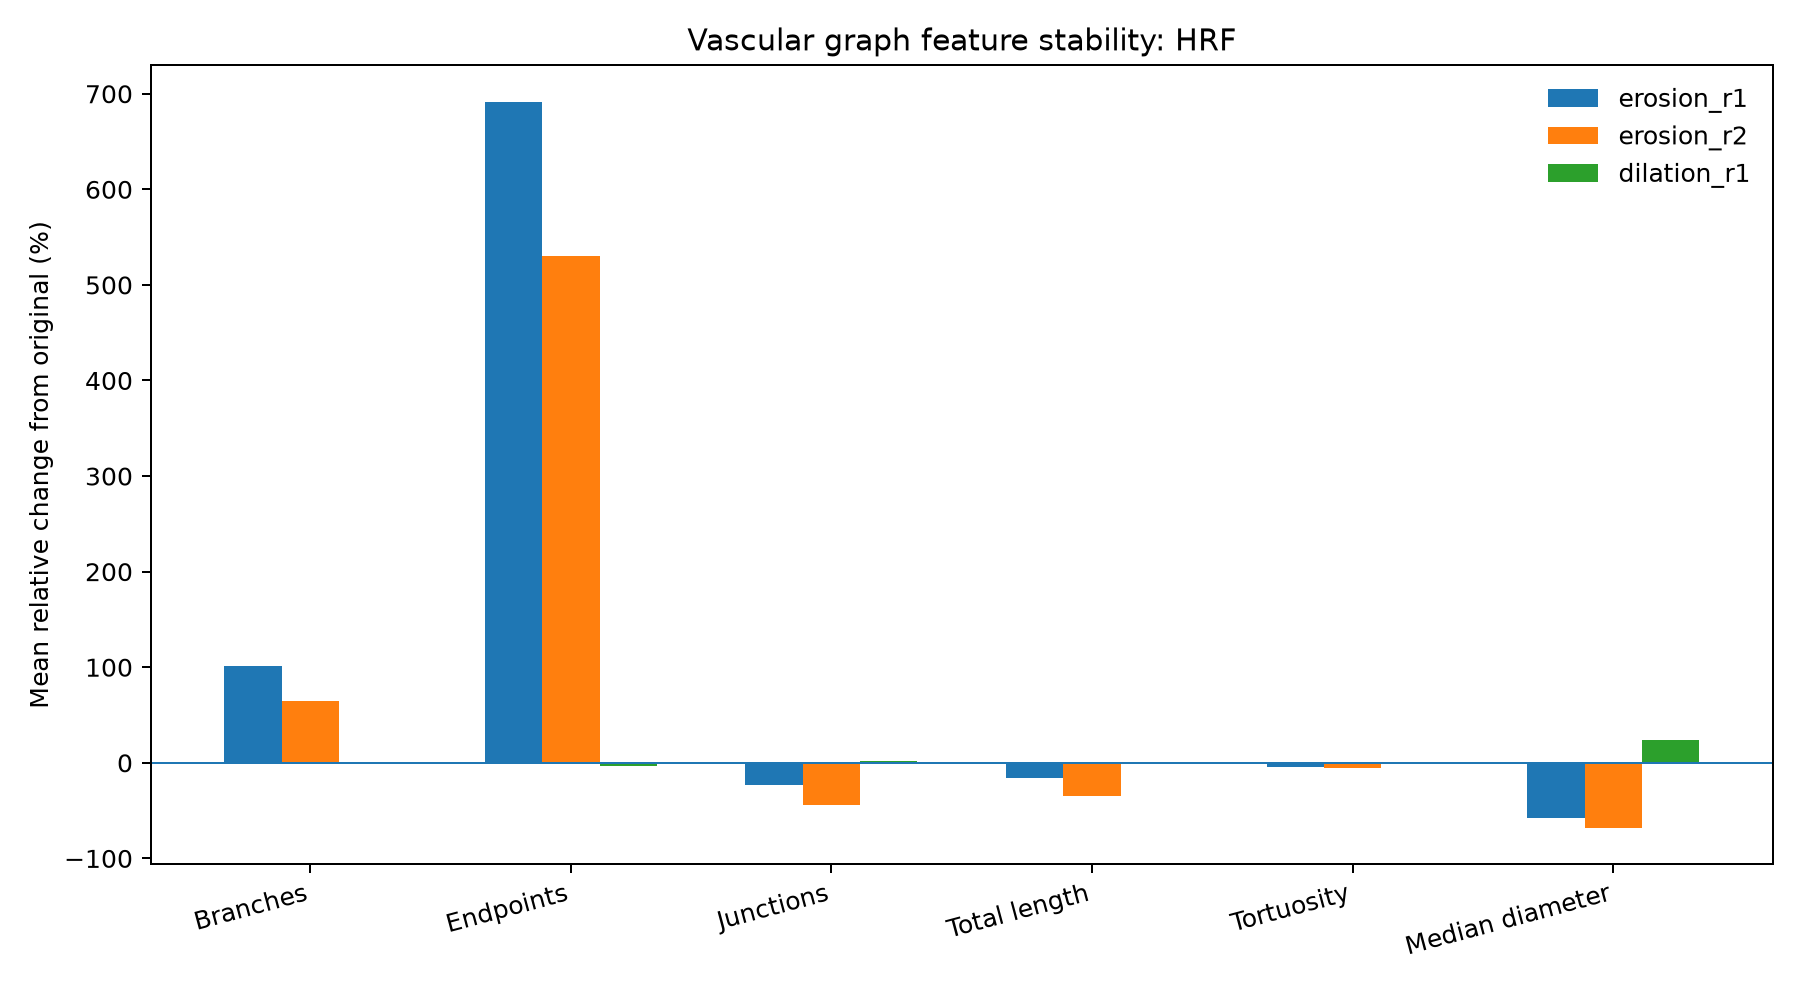

In [5]:
display(per_image.groupby(["dataset", "condition"])[["branch_count", "endpoint_count", "junction_count", "total_branch_length_px", "mean_tortuosity", "median_vessel_diameter_px"]].mean())
display(branch_features.head(10))

from IPython.display import Image, display
for dataset in summary["dataset"].drop_duplicates():
    display(Image(filename=str(RESULTS / "figures" / f"{dataset.lower()}_graph_stability.png")))

## Reproducibility and interpretation

GraphML files for original masks and the per-image and per-branch tables are saved under `results/`. Relative changes are summarized separately for HRF and CHASE_DB1 because their image resolutions and field-of-view handling differ. The first CHASE_DB1 human annotation is used consistently.